# Embeddings Workshop — Numerical Representation of Data

## What is an embedding?

An **embedding** maps an object (a word, a sentence, an image) to a fixed-length
vector of numbers such that *similar objects end up close together* in that space.

```
"dog is eating sth"   → [ 0.12, -0.45,  0.88, … ]   (some vector of numbers)
"puppy is eathing sth" → [ 0.11, -0.47,  0.91, … ]   ← very close to the previous sentence !
"car is driving through a road"   → [-0.72,  0.33, -0.15, … ]   ← far away
```

Once data lives in a vector space we can use standard geometry (dot products,
distances) to answer the question *"what is most similar to X?"*.

## Workshop structure

| Section | Who writes it |
|---------|---------------|
| **Core helper functions** | Pre-built — read & understand them |
| **Part 1 — Text** | **You** implement `vectorize_texts(texts)` |
| **Part 2 — Images** | **You** implement `vectorize_images(images)` |
| **Instructor reference** | Example solutions shown at the bottom |

**Rule:** only edit cells marked 🎯 YOUR TASK. All other cells run unchanged.

In [1]:
# Run once — installs everything needed for the full notebook (including instructor examples)
# %pip install -q datasets timm sentence-transformers scikit-learn Pillow torch torchvision pandas
# pip install "jupyter>=1.1.1" "matplotlib>=3.10.9" "numpy>=2.4.4" "pandas>=3.0.2" "pillow>=12.2.0" "scikit-learn>=1.8.0" "sentence-transformers>=5.4.1" "timm>=1.0.26" "torchvision>=0.26.0""datasets<4.0.0

In [2]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from typing import Literal
from PIL import Image

In [3]:
def find_similar(
    query_vector: np.ndarray,
    database_matrix: np.ndarray,
    metric: Literal["cosine", "dot", "mse"] = "cosine",
    top_k: int = 5,
) -> tuple[np.ndarray, np.ndarray]:
    """Search a database of embeddings for the closest matches to a query vector.

    Given a 1-D query embedding and a 2-D database of stored embeddings, this
    function scores every row in the database against the query using the chosen
    metric, then returns the row indices and scores of the ``top_k`` most similar
    items in descending order (most similar first).

    Parameters
    ----------
    query_vector : np.ndarray, shape (d,)
        The embedding of the item you want to find matches for.
        Must be a 1-D array whose length equals the number of columns in
        ``database_matrix``.

    database_matrix : np.ndarray, shape (n, d)
        Matrix of stored embeddings — one embedding per row.
        ``n`` is the number of stored items; ``d`` is the embedding dimension
        and must match ``query_vector``.

    metric : {'cosine', 'dot', 'mse'}, default 'cosine'
        Similarity function to use.

        cosine
            Cosine similarity.  Both vectors are L2-normalised before the dot
            product, so the score is in **[-1, 1]** and is independent of
            vector magnitude.  Use this as your default.

        dot
            Raw dot product (higher ⇒ more similar).  Sensitive to magnitude,
            so embeddings should already be unit-normalised if comparability
            across items matters.

        mse
            Negative Mean Squared Error:
            ``score = -mean((database_row - query_vector) ** 2)``.
            Scores are ≤ 0; less negative means more similar.  The sign flip
            keeps the API consistent: **higher score always means more similar**
            regardless of which metric you choose.

    top_k : int, default 5
        Number of results to return.  Must not exceed the number of rows in
        ``database_matrix``.

    Returns
    -------
    indices : np.ndarray, shape (top_k,)
        Row indices of the most similar items in ``database_matrix``, ordered
        from most to least similar.

    scores : np.ndarray, shape (top_k,)
        Similarity score for each returned index.

    Raises
    ------
    ValueError
        If ``query_vector`` is not 1-D.
    ValueError
        If ``database_matrix`` is not 2-D.
    ValueError
        If the dimensionality of ``query_vector`` does not match the number of
        columns in ``database_matrix`` (shape mismatch).
    ValueError
        If ``top_k`` is larger than the number of rows in ``database_matrix``.
    ValueError
        If ``metric`` is not one of the recognised strings.

    Examples
    --------
    >>> import numpy as np
    >>> query = np.array([1.0, 0.0, 0.0])
    >>> db    = np.array([[1.0,  0.0, 0.0],   # identical to query
    ...                   [0.0,  1.0, 0.0],   # orthogonal
    ...                   [-1.0, 0.0, 0.0]])  # opposite direction
    >>> indices, scores = find_similar(query, db, metric="cosine", top_k=3)
    >>> indices
    array([0, 1, 2])
    >>> np.round(scores, 4)
    array([ 1.,  0., -1.])
    """
    # ── Validate inputs ───────────────────────────────────────────────────────
    if query_vector.ndim != 1:
        raise ValueError(
            f"query_vector must be 1-D, got shape {query_vector.shape}."
        )
    if database_matrix.ndim != 2:
        raise ValueError(
            f"database_matrix must be 2-D, got shape {database_matrix.shape}."
        )
    q_dim  = query_vector.shape[0]
    db_dim = database_matrix.shape[1]
    if q_dim != db_dim:
        raise ValueError(
            f"Dimension mismatch: query_vector has {q_dim} features but "
            f"database_matrix has {db_dim} features "
            f"(database_matrix.shape = {database_matrix.shape})."
        )
    if top_k > database_matrix.shape[0]:
        raise ValueError(
            f"top_k={top_k} exceeds the number of items in database_matrix "
            f"({database_matrix.shape[0]} rows)."
        )

    # ── Compute similarity scores ─────────────────────────────────────────────
    if metric == "cosine":
        eps     = 1e-10  # guards against zero-vector division
        q_unit  = query_vector / (np.linalg.norm(query_vector) + eps)
        db_unit = database_matrix / (
            np.linalg.norm(database_matrix, axis=1, keepdims=True) + eps
        )
        scores = db_unit @ q_unit

    elif metric == "dot":
        scores = database_matrix @ query_vector

    elif metric == "mse":
        # Negate so "higher = more similar" stays consistent across all metrics
        scores = -np.mean((database_matrix - query_vector) ** 2, axis=1)

    else:
        raise ValueError(
            f"Unknown metric {metric!r}. Choose from 'cosine', 'dot', 'mse'."
        )

    # ── Rank and return ───────────────────────────────────────────────────────
    top_indices = np.argsort(scores)[::-1][:top_k]
    return top_indices, scores[top_indices]

In [4]:
def visualize_image_search(
    query_image: Image.Image,
    result_images: list[Image.Image],
    result_scores: np.ndarray,
    result_labels: list[str] | None = None,
    figsize_per_image: tuple[float, float] = (3.0, 3.5),
) -> None:
    """Display a query image side-by-side with its closest matches.

    Parameters
    ----------
    query_image : PIL.Image.Image
        The image used as the search query.
    result_images : list of PIL.Image.Image
        Retrieved images in rank order (most similar first).
    result_scores : np.ndarray, shape (k,)
        Similarity score for each retrieved image.
    result_labels : list of str, optional
        Human-readable class name for each result.  Omit to show scores only.
    figsize_per_image : tuple of float, default (3.0, 3.5)
        Width × height (inches) allocated to each image panel.
    """
    n = len(result_images)
    fig, axes = plt.subplots(
        1, n + 1,
        figsize=(figsize_per_image[0] * (n + 1), figsize_per_image[1]),
    )

    axes[0].imshow(query_image)
    axes[0].set_title("Query", fontsize=11, fontweight="bold", color="steelblue")
    axes[0].axis("off")

    for rank, (img, score) in enumerate(zip(result_images, result_scores), start=1):
        ax  = axes[rank]
        ax.imshow(img)
        lbl = f"\n{result_labels[rank - 1]}" if result_labels else ""
        ax.set_title(f"#{rank}{lbl}\nScore: {score:.3f}", fontsize=9)
        ax.axis("off")

    plt.suptitle("Image Similarity Search Results", fontsize=13, y=1.02, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [11]:
def print_text_results(
    query_text: str,
    result_texts: list[str],
    result_scores: np.ndarray,
    max_chars: int = 200,
) -> None:
    """Pretty-print text similarity search results with scores.

    Parameters
    ----------
    query_text : str
        The text used as the search query.
    result_texts : list of str
        Retrieved texts in rank order (most similar first).
    result_scores : np.ndarray, shape (k,)
        Similarity score for each retrieved text.
    max_chars : int, default 200
        Maximum characters shown per snippet.
    """
    bar = "─" * 72
    print(f"\n{'=' * 72}")
    print("  QUERY")
    print(f"{'=' * 72}")
    print(query_text[:max_chars].replace("\n", " "))
    print()
    print(f"  TOP {len(result_texts)} RESULTS")
    print(bar)
    for rank, (text, score) in enumerate(zip(result_texts, result_scores), start=1):
        snippet  = text[:max_chars].replace("\n", " ")
        ellipsis = "…" if len(text) > max_chars else ""
        print(f"  #{rank}  |  Score: {score:+.4f}")
        print(f"  {snippet}{ellipsis}")
        print(bar)

In [5]:
# pip install datasets
from datasets import load_dataset

# Load the dataset
dataset = load_dataset("fancyzhx/dbpedia_14", split="train")

# Convert to list to match your 'texts' and 'text_labels' structure
texts = dataset['content'][:400]
texts = [texts[0]] + texts

label_names = dataset.features['label'].names
text_labels = [label_names[i] for i in dataset['label'][:400]]

print(f"Categories: {label_names}")
print(f"Sample (category={text_labels[0]}): {texts[0][:200]}...")

Categories: ['Company', 'EducationalInstitution', 'Artist', 'Athlete', 'OfficeHolder', 'MeanOfTransportation', 'Building', 'NaturalPlace', 'Village', 'Animal', 'Plant', 'Album', 'Film', 'WrittenWork']
Sample (category=Company):  Abbott of Farnham E D Abbott Limited was a British coachbuilding business based in Farnham Surrey trading under that name from 1929. A major part of their output was under sub-contract to motor vehic...


In [6]:
texts[3]

' Q-workshop is a Polish company located in Poznań that specializes in designand production of polyhedral dice and dice accessories for use in various games (role-playing gamesboard games and tabletop wargames). They also run an online retail store and maintainan active forum community.Q-workshop was established in 2001 by Patryk Strzelewicz – a student from Poznań. Initiallythe company sold its products via online auction services but in 2005 a website and online store wereestablished.'

---
## Part 1 — Text Similarity Search

We load a subset of the **20 Newsgroups** dataset: ~400 newsgroup posts spread
across 4 topic categories.  Your vectorizer will turn each post into a vector
so we can find posts on similar topics.

### 🎯 YOUR TASK — Text Vectorizer

Implement the function `vectorize_texts` in the cell below.

**Contract**

| | |
|---|---|
| **Input** | `texts` — a Python `list` of `n` strings (the full corpus including the query) |
| **Output** | `np.ndarray` of shape `(n, vector_size)` — one row per text |
| **Rule** | Every row must have the **same** `vector_size` (your choice) |

Because the entire dataset is passed at once (query at index 0, database at
indices 1 …), you can use **corpus-level information** like the total vocabulary.

**Ideas** (from simple → complex):
- Count how often each letter `a–z` appears → 26-D vector
- Count how often each of the 500 most common English words appears
- Binary flags: does the text contain any of a hand-picked list of keywords?
- Normalised character n-gram frequencies


In [ ]:
def vectorize_texts(texts: list[str]) -> np.ndarray:
    """Convert a list of texts into a matrix of embedding vectors.

    Parameters
    ----------
    texts : list of str
        Corpus to vectorize.  texts[0] is the query; texts[1:] are the database.

    Returns
    -------
    np.ndarray, shape (len(texts), vector_size)
        Each row is the embedding of the corresponding text.
        All rows must have the same length.
    """
    # ╔══════════════════════════════════════════════════╗
    # ║              🎯  YOUR CODE HERE                  ║
    # ╚══════════════════════════════════════════════════╝

    raise NotImplementedError("Implement vectorize_texts!")

### Run the text search

After implementing `vectorize_texts` above, run this cell to see the results.

- Change `QUERY_IDX` to search with a different document.
- Change `METRIC` to experiment with different similarity functions.

In [76]:
QUERY_IDX = 0         # index of the document to use as query (0–399)
TOP_K     = 5         # how many results to retrieve
METRIC    = "mse"  # "cosine" | "dot" | "mse"

# Build the input list: query at position 0, database after
query_text = texts[QUERY_IDX]
db_texts   = [t for i, t in enumerate(texts)       if i != QUERY_IDX]
db_labels  = [l for i, l in enumerate(text_labels) if i != QUERY_IDX]

# Vectorize everything at once so corpus-level methods (e.g. TF-IDF) see
# the full vocabulary
all_vectors = vectorize_texts([query_text] + db_texts)  # shape: (n+1, d)

query_vec = all_vectors[0]   # embedding of the query
db_matrix = all_vectors[1:]  # shape: (n, d)

# Search
indices, scores = find_similar(query_vec, db_matrix, metric=METRIC, top_k=TOP_K)

result_texts  = [db_texts[i]  for i in indices]
result_labels = [db_labels[i] for i in indices]

print(f"Query category : {text_labels[QUERY_IDX]!r}")
print(f"Result categories: {result_labels}")
print_text_results(query_text, result_texts, scores)

Query category : 'Company'
Result categories: ['Company', 'Company', 'Company', 'Company', 'Company']

  QUERY
 Abbott of Farnham E D Abbott Limited was a British coachbuilding business based in Farnham Surrey trading under that name from 1929. A major part of their output was under sub-contract to motor vehic

  TOP 5 RESULTS
────────────────────────────────────────────────────────────────────────
  #1  |  Score: -0.0000
   Abbott of Farnham E D Abbott Limited was a British coachbuilding business based in Farnham Surrey trading under that name from 1929. A major part of their output was under sub-contract to motor vehic…
────────────────────────────────────────────────────────────────────────
  #2  |  Score: -0.0008
   Donald Healey Motor Company Limited was a British car manufacturer.
────────────────────────────────────────────────────────────────────────
  #3  |  Score: -0.0009
   Cherokee Studios was a recording facility in Hollywood founded in 1972 and closed in August 2007 to ma

In [77]:
scores

array([-0.        , -0.00079425, -0.00087119, -0.00087151, -0.00088057],
      dtype=float32)

---
## Part 2 — Image Similarity Search

We load a 100-image sample from **Caltech101** via `torchvision.datasets.Caltech101` — the dataset downloads automatically on first run, no manual setup needed.
Images are identified by their Caltech101 category name (e.g. `sunflower`, `zebra`).

> **Note:** On first run, torchvision will download and extract the dataset to `./data` automatically.

Loading Caltech101 dataset...
Collected 200 images across 20 classes


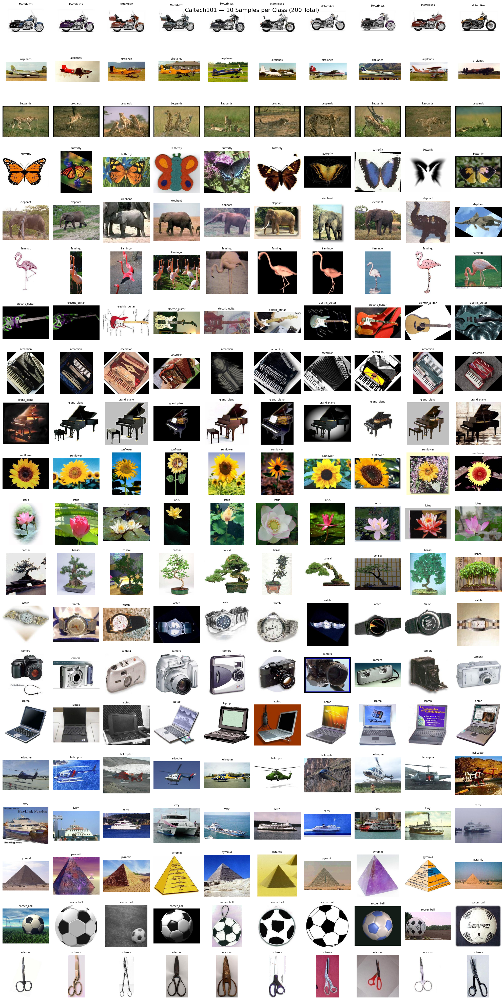

Counter({'Motorbikes': 10, 'airplanes': 10, 'Leopards': 10, 'butterfly': 10, 'elephant': 10, 'flamingo': 10, 'electric_guitar': 10, 'accordion': 10, 'grand_piano': 10, 'sunflower': 10, 'lotus': 10, 'bonsai': 10, 'watch': 10, 'camera': 10, 'laptop': 10, 'helicopter': 10, 'ferry': 10, 'pyramid': 10, 'soccer_ball': 10, 'scissors': 10})


In [27]:
import torchvision
import matplotlib.pyplot as plt

# 1. Define Caltech101 class mapping (subset of 20 diverse classes)
diverse_classes = [
    "Motorbikes", "airplanes", "Leopards",        # vehicles & animals
    "butterfly", "elephant", "flamingo",           # nature & animals
    "electric_guitar", "accordion", "grand_piano", # instruments
    "sunflower", "lotus", "bonsai",                # plants
    "watch", "camera", "laptop",                   # devices
    "helicopter", "ferry", "pyramid",              # structures & transport
    "soccer_ball", "scissors"                      # objects
]

IMAGES_PER_CLASS = 10  # 20 classes × 10 = 200 images total

# 2. Load Caltech101 via torchvision (downloads automatically)
print("Loading Caltech101 dataset...")
dataset = torchvision.datasets.Caltech101(root='./data', download=True)

# 3. Build a mapping from class name → indices
class_to_indices = {}
for idx, (_, label_idx) in enumerate(dataset):
    label_name = dataset.categories[label_idx]
    if label_name in diverse_classes:
        class_to_indices.setdefault(label_name, []).append(idx)

# 4. Collect up to 10 samples per class (200 total)
images = []
image_labels = []

for class_name in diverse_classes:
    indices = class_to_indices.get(class_name, [])[:IMAGES_PER_CLASS]
    for idx in indices:
        img, label_idx = dataset[idx]
        images.append(img.convert("RGB") if hasattr(img, "convert") else img)
        image_labels.append(class_name)

print(f"Collected {len(images)} images across {len(diverse_classes)} classes")

# 5. Visualization — 20 rows × 10 cols
rows, cols = 20, 10
fig, axes = plt.subplots(rows, cols, figsize=(20, 40))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        ax.imshow(images[i])
        ax.set_title(image_labels[i], fontsize=7)
    ax.axis('off')

plt.suptitle("Caltech101 — 10 Samples per Class (200 Total)", fontsize=16)
plt.tight_layout()
plt.show()

# 6. Verify distribution
from collections import Counter
print(Counter(image_labels))

### 🎯 YOUR TASK — Image Vectorizer

Implement the function `vectorize_images` in the cell below.

**Contract**

| | |
|---|---|
| **Input** | `images` — a Python `list` of `n` PIL `RGB` images (sizes may vary) |
| **Output** | `np.ndarray` of shape `(n, vector_size)` — one row per image |
| **Rule** | Every row must have the **same** `vector_size` (your choice) |

**Ideas** (from simple → complex):
- Resize every image to 8×8 and flatten → 8×8×3 = 192-D vector
- Compute the average R, G, B values → 3-D vector
- Count pixels in brightness bins (histogram) → e.g. 32-D per channel
- Flatten a small grayscale version of the image

In [ ]:
def vectorize_images(images: list[Image.Image]) -> np.ndarray:
    """Convert a list of PIL images into a matrix of embedding vectors.

    Parameters
    ----------
    images : list of PIL.Image.Image
        Images to vectorize (all already in RGB mode).
        images[0] is the query; images[1:] are the database.

    Returns
    -------
    np.ndarray, shape (len(images), vector_size)
        Each row is the embedding of the corresponding image.
        All rows must have the same length.
    """
    # ╔══════════════════════════════════════════════════╗
    # ║              🎯  YOUR CODE HERE                  ║
    # ╚══════════════════════════════════════════════════╝

    raise NotImplementedError("Implement vectorize_images!")

### Run the image search

After implementing `vectorize_images` above, run this cell.

- Change `QUERY_IMG_IDX` to search with a different image.

Query label: 'Motorbikes'


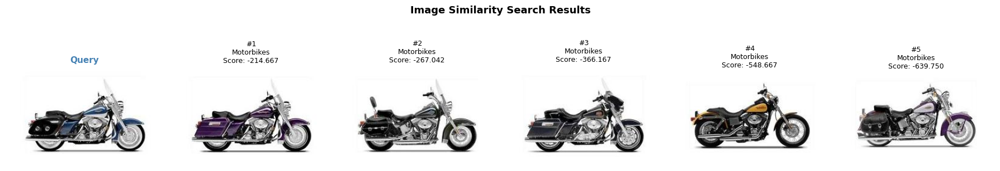

In [78]:
QUERY_IMG_IDX = 0        # index of the image to use as query (0–99)
TOP_K_IMGS    = 5         # how many results to retrieve
METRIC_IMGS   = "mse"  # "cosine" | "dot" | "mse"

# Build the input list: query at position 0, database after
query_image = images[QUERY_IMG_IDX]
db_images   = [img for i, img in enumerate(images)       if i != QUERY_IMG_IDX]
db_img_lbls = [lbl for i, lbl in enumerate(image_labels) if i != QUERY_IMG_IDX]

# Vectorize everything at once
all_img_vectors = vectorize_images([query_image] + db_images)  # shape: (n+1, d)

query_img_vec = all_img_vectors[0]   # query embedding
db_img_matrix = all_img_vectors[1:]  # shape: (n, d)

# Search
img_indices, img_scores = find_similar(
    query_img_vec, db_img_matrix, metric=METRIC_IMGS, top_k=TOP_K_IMGS
)

result_images = [db_images[i]   for i in img_indices]
result_labels = [db_img_lbls[i] for i in img_indices]

print(f"Query label: {image_labels[QUERY_IMG_IDX]!r}")
visualize_image_search(query_image, result_images, img_scores, result_labels)

In [42]:
# all_img_vectors.ndim
img_scores

array([-11865.708, -16413.041, -18165.438, -19694.938, -20389.812],
      dtype=float32)